In [11]:
import os
import sys
from multiprocessing import Pool
from copy import deepcopy

import pandas as pd
import sqlite3
import cv2
import numpy as np
import tqdm
import time
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

import video_similarity.group_images as group_images

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
DB_PATH = "people_detection.db"
SEQ_CSV_PATH = "seq_files.csv"
RES_FOLDER_PATH = "embeddings_full"

os.makedirs(RES_FOLDER_PATH, exist_ok=True)

In [3]:
SIM_LEVELS = [1, 10, 20, 30, 50]


In [4]:
def process_avi(avi_pth):
    N = 100
    cap = cv2.VideoCapture(avi_pth)

    frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frames.append(frame)
    frames = frames[N:-N]

    cap.release()

    embedder = group_images.Embedder()
    embeddings = [embedder.extract_embedding_from_img(frame).detach().numpy()[0] for frame in frames]

    file_path = os.path.join(RES_FOLDER_PATH, os.path.splitext(os.path.basename(avi_pth))[0])
    with open(file_path, "wb") as f:
        np.save(f, embeddings)

In [5]:
def compute_similarity(vectors, sim_func, dist):
    # Number of vectors
    N = len(vectors)
    
    # List to store similarity values
    similarity_values = []
    
    # Iterate over vectors with the specified distance
    for i in range(N - dist):
        # Compute similarity between vectors i and i + dist
        sim = sim_func(vectors[i], vectors[i + dist])
        similarity_values.append(sim)
    
    return np.array(similarity_values)

def f_sim(x, y):
    return cosine_distances([x], [y])[0, 0]

In [6]:
df = pd.read_csv(SEQ_CSV_PATH)
avi_paths = df["avi_path"].values

np.random.seed(42)
np.random.shuffle(avi_paths)
print(avi_paths[:5])

['/mnt/pg-fs02/Public/DB_Team/PG1/0_Orange_IT/0_2Move2db/PG1_2018_03_25_H400_DL_Desk_W_carpet_W_Upload_20180329_TP5850_tag_1483764_20180310/done/PG1_DL_H400_Desk_W_Carpet_W_NY_180320-171725.avi'
 '/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/Occupancy/OCS_CP_AlgoDev_DLtest_cg_B_PIRar/H350_BatzraOfficeStyle_act_09_12_20_34_2016.avi'
 '/mnt/pg-fs02/Public/DB_Team/PG1/0_Orange_IT/0_2Check/Priority1/done/PG1_dev_2018_05_03_HD_stnd_NY_Upload_20180523_TP15800_tag_1271501_20180611_done/done/PG1_dev_H300_HD_NY_stnd_20180511_1525098114.avi'
 '/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_OBJECT/PG1_Office_Object_All_Desk/PG1_DL_Object_H300_FullDesk_Wood_180522R04_06_Vac_180516-161259.avi'
 '/mnt/pg-fs02/Public/DB_Team/PG1/0_Orange_IT/0_2Move2db/ADD_AREA/PG1_2017_10_22_DV_H300_HD_Static_Occlusion_NY_Upload_17_10_23_tag_368302_171123_done/DONE/PG1_H300_HD_Static_NY_1508322358.avi']


 40%|████      | 2/5 [00:13<00:21,  7.05s/it]

Device: cuda


/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
 60%|██████    | 3/5 [02:12<01:56, 58.35s/it]

Device: cuda


/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
 80%|████████  | 4/5 [03:24<01:03, 63.49s/it]

Device: cuda


/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
100%|██████████| 5/5 [05:35<00:00, 67.15s/it]


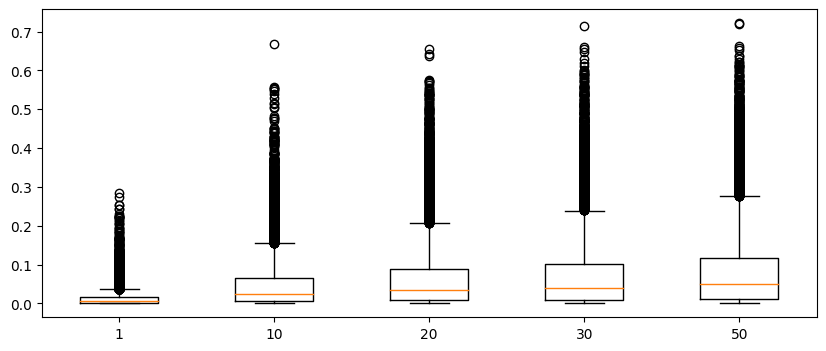

In [9]:
values = {}
for i in SIM_LEVELS:
    values[i] = []

for avi_pth in tqdm.tqdm(avi_paths[:5]):
    emb_pth = os.path.join(RES_FOLDER_PATH, os.path.splitext(os.path.basename(avi_pth))[0])
    
    if not os.path.exists(emb_pth):
        process_avi(avi_pth)

    with open(emb_pth, "rb") as f:
        embeddings = np.load(f)
    
    for sim_l in SIM_LEVELS:
        values[sim_l].append(compute_similarity(embeddings, f_sim, sim_l))


res = deepcopy(values)

for i in res:
    res[i] = np.concatenate(res[i])

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(res.values())
ax.set_xticklabels(res.keys());

  0%|          | 0/15 [00:00<?, ?it/s]

 33%|███▎      | 5/15 [00:37<01:14,  7.43s/it]

Device: cuda


/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
 40%|████      | 6/15 [02:22<06:06, 40.76s/it]

Device: cuda


...

/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
 87%|████████▋ | 13/15 [13:41<02:41, 80.79s/it]

Device: cuda


/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
 93%|█████████▎| 14/15 [15:44<01:33, 93.47s/it]

Device: cuda


/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
100%|██████████| 15/15 [17:07<00:00, 68.50s/it]


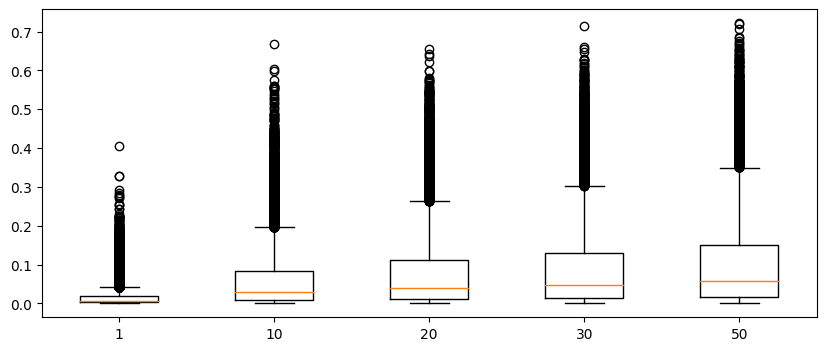

In [10]:
values = {}
for i in SIM_LEVELS:
    values[i] = []

for avi_pth in tqdm.tqdm(avi_paths[:15]):
    emb_pth = os.path.join(RES_FOLDER_PATH, os.path.splitext(os.path.basename(avi_pth))[0])
    
    if not os.path.exists(emb_pth):
        process_avi(avi_pth)

    with open(emb_pth, "rb") as f:
        embeddings = np.load(f)
    
    for sim_l in SIM_LEVELS:
        values[sim_l].append(compute_similarity(embeddings, f_sim, sim_l))


res = deepcopy(values)

for i in res:
    res[i] = np.concatenate(res[i])

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(res.values())
ax.set_xticklabels(res.keys());